In [2]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu') 

In [3]:
# read in all the words
words = open('names.txt', 'r').read().splitlines()
words[:3]

['emma', 'olivia', 'ava']

In [4]:
len(words)

32035

In [5]:
# build the vocabulary of character mappings to/from integers 
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [6]:
# build the dataset
block_size = 10 # context length: how many characters do we take to predict the next one?

def build_dataset(words):  
  X, Y = [], []
  for w in words:

    #print(w)
    context = [0] * block_size # This used to take the starting value '.' inside the block
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      #print(''.join(itos[i] for i in context), '--->', itos[ix])
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X, device=device)
  Y = torch.tensor(Y, device=device)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(99)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

# Splitting the dataset into (Training, Validate, Test)
Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

# training split, dev/validation split, test split
# 80%, 10%, 10%

torch.Size([182438, 10]) torch.Size([182438])
torch.Size([22878, 10]) torch.Size([22878])
torch.Size([22841, 10]) torch.Size([22841])


In [7]:
Xtr.shape, Xtr.dtype, Ytr.shape, Ytr.dtype

(torch.Size([182438, 10]), torch.int64, torch.Size([182438]), torch.int64)

In [8]:
C = torch.randn(27, 5, device=device)
'''NOTE: now to see the vector made in C for our 27 characters we can just use 'C[5]' Which will give us the 5th row from the matrix
   that is the simple way what we can also do is we can use 'F.one_hot()' to convert this into a matrix of dim 27
   where only the 5th element is toggled to 1 other are 0 and we can do matrix multiplication with 'C' this will also create the same result
   following the rersearch paper we stick to lookup.'''

"NOTE: now to see the vector made in C for our 27 characters we can just use 'C[5]' Which will give us the 5th row from the matrix\n   that is the simple way what we can also do is we can use 'F.one_hot()' to convert this into a matrix of dim 27\n   where only the 5th element is toggled to 1 other are 0 and we can do matrix multiplication with 'C' this will also create the same result\n   following the rersearch paper we stick to lookup."

In [9]:
C

tensor([[ 1.4926e+00, -1.8398e+00, -2.6126e+00, -7.7317e-01,  2.6664e-01],
        [ 1.1687e+00, -6.6654e-01, -4.3992e-01, -2.0082e+00, -8.6029e-01],
        [ 3.7812e-01, -7.4036e-01,  9.6155e-01, -1.9849e+00,  1.0902e+00],
        [ 1.0786e+00,  3.2217e-01,  3.2149e-01, -1.3282e+00, -3.2262e-01],
        [ 8.1355e-01, -4.8289e-01, -1.4783e-02,  9.5080e-01, -7.5673e-01],
        [-1.0176e+00,  8.3745e-02, -1.3855e-01,  1.4423e-01, -2.8933e-01],
        [-1.9444e-01,  1.6461e-03,  2.6988e-01,  1.7962e-01, -9.6290e-01],
        [ 5.0644e-01, -2.9101e-01,  3.5029e-01,  9.1799e-01, -3.7698e-01],
        [ 1.7411e-01, -1.1193e+00, -3.7656e-01,  2.5538e+00, -8.3125e-01],
        [ 6.9893e-01,  2.5450e-01,  1.7133e+00, -4.4346e-01,  5.7526e-01],
        [ 5.1969e-02,  3.9105e-02, -1.3993e+00,  2.6333e-01, -2.7810e-01],
        [-2.7718e+00,  2.0234e-01, -3.1539e-01,  1.2828e+00,  6.4470e-01],
        [-1.4863e-01,  2.6505e-01, -7.8262e-02, -4.9938e-01,  2.5633e+00],
        [-1.4097e+00,  1.

In [10]:
C[5] # Following the paper using this 

tensor([-1.0176,  0.0837, -0.1386,  0.1442, -0.2893], device='cuda:0')

In [11]:
F.one_hot(torch.tensor(5, device=device), num_classes=27).float() @ C

tensor([-1.0176,  0.0837, -0.1386,  0.1442, -0.2893], device='cuda:0')

In [12]:
# indexing
C[Xtr] # [32, 3, 5]

tensor([[[ 1.4926, -1.8398, -2.6126, -0.7732,  0.2666],
         [ 1.4926, -1.8398, -2.6126, -0.7732,  0.2666],
         [ 1.4926, -1.8398, -2.6126, -0.7732,  0.2666],
         ...,
         [ 1.4926, -1.8398, -2.6126, -0.7732,  0.2666],
         [ 1.4926, -1.8398, -2.6126, -0.7732,  0.2666],
         [ 1.4926, -1.8398, -2.6126, -0.7732,  0.2666]],

        [[ 1.4926, -1.8398, -2.6126, -0.7732,  0.2666],
         [ 1.4926, -1.8398, -2.6126, -0.7732,  0.2666],
         [ 1.4926, -1.8398, -2.6126, -0.7732,  0.2666],
         ...,
         [ 1.4926, -1.8398, -2.6126, -0.7732,  0.2666],
         [ 1.4926, -1.8398, -2.6126, -0.7732,  0.2666],
         [ 0.5064, -0.2910,  0.3503,  0.9180, -0.3770]],

        [[ 1.4926, -1.8398, -2.6126, -0.7732,  0.2666],
         [ 1.4926, -1.8398, -2.6126, -0.7732,  0.2666],
         [ 1.4926, -1.8398, -2.6126, -0.7732,  0.2666],
         ...,
         [ 1.4926, -1.8398, -2.6126, -0.7732,  0.2666],
         [ 0.5064, -0.2910,  0.3503,  0.9180, -0.3770],
  

In [13]:
C[Xtr][13,2]

tensor([ 1.4926, -1.8398, -2.6126, -0.7732,  0.2666], device='cuda:0')

In [14]:
Xtr[13,2]

tensor(0, device='cuda:0')

In [15]:
C[1]

tensor([ 1.1687, -0.6665, -0.4399, -2.0082, -0.8603], device='cuda:0')

In [16]:
# Layer 1
emb = C[Xtr]
emb.shape

torch.Size([182438, 10, 5])

In [17]:
# Hidden Layer
W1 = torch.randn((50, 150), device=device)
b1 = torch.randn((150), device=device)

In [18]:
h = torch.tanh(emb.view(-1, 50) @ W1 + b1)

In [19]:
h

tensor([[ 1.0000,  1.0000,  0.7362,  ..., -1.0000,  0.9827, -1.0000],
        [ 0.2397,  1.0000, -0.9986,  ..., -1.0000,  0.9931, -1.0000],
        [-1.0000,  1.0000, -0.9988,  ..., -1.0000,  0.9967, -1.0000],
        ...,
        [-0.9981,  1.0000, -1.0000,  ..., -1.0000,  1.0000, -0.8497],
        [ 0.5718,  1.0000, -0.9952,  ..., -1.0000,  1.0000, -1.0000],
        [-0.9979,  1.0000, -1.0000,  ..., -1.0000,  1.0000, -0.9736]],
       device='cuda:0')

In [20]:
h.shape

torch.Size([182438, 150])

In [21]:
# Final Layer
W2 = torch.randn((150, 27), device=device)
b2 = torch.randn((27), device=device)

In [22]:
logits = h @ W2 + b2

In [23]:
logits.shape 

torch.Size([182438, 27])

In [24]:
counts = logits.exp()

In [25]:
prob = counts / counts.sum(1, keepdims=True)

In [26]:
prob.shape

torch.Size([182438, 27])

In [27]:
# loss = -prob[torch.arange(182566), Ytr].log().mean() # negative log_likelihood
# loss

In [28]:
# ------------ now made respectable :) ---------------

In [29]:
Xtr.shape, Ytr.shape # dataset

(torch.Size([182438, 10]), torch.Size([182438]))

In [30]:
C = torch.randn((27, 30), device=device, requires_grad=True)

W1 = (torch.randn((300, 200), device=device) * (5/3) / (200**0.5)).requires_grad_()
b1 = torch.zeros(200, device=device, requires_grad=True)

W2 = (torch.randn((200, 27),  device=device) * 0.01).requires_grad_()
b2 = torch.zeros(27, device=device, requires_grad=True)

parameters = [C, W1, b1, W2, b2]

In [31]:
sum(p.nelement() for p in parameters) # number of parameters in total

66437

In [32]:
for name, p in zip(["C", "W1", "b1", "W2", "b2"], parameters):
    print(
        f"{name}: mean={p.mean().item():.4f}, "
        f"std={p.std().item():.4f}, "
        f"min={p.min().item():.4f}, "
        f"max={p.max().item():.4f}"
    )

C: mean=0.0624, std=1.0092, min=-3.1892, max=3.3499
W1: mean=-0.0002, std=0.1176, min=-0.5028, max=0.4618
b1: mean=0.0000, std=0.0000, min=0.0000, max=0.0000
W2: mean=0.0000, std=0.0100, min=-0.0370, max=0.0377
b2: mean=0.0000, std=0.0000, min=0.0000, max=0.0000


In [33]:
for p in parameters:
  p.requires_grad = True

In [34]:
# trying the learning rates
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre

In [420]:
# older code 
for i in range(1):
  
  # Minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (32,), device=device)
  
  # Forward pass
  emb = C[Xtr[ix]] # (32, 10, 30)
  h = torch.tanh(emb.view(-1, 300) @ W1 + b1) # (32, 300)
  logits = h @ W2 + b2 # (32, 27)
  loss = F.cross_entropy(logits, Ytr[ix])
  
  # Backward pass
  for p in parameters:
    p.grad = None
  loss.backward()
  
  # Update (learning rate decay)
  #lr = lrs[i]
  lr = 0.1 if i < 100000 else 0.01
  with torch.no_grad():
    for p in parameters:
        p -= lr * p.grad

  # Track stats
  #lri.append(lre[i])
  stepi.append(i)
  lossi.append(loss.log10().item())

print(loss.item())

1.7076926231384277


In [35]:
import copy
import torch
import torch.nn.functional as F

# Track the best model
best_val_loss = float('inf')
best_step = 0
best_parameters = None

# Track losses
stepi = []
lossi = []
train_history = []
val_history = []


@torch.no_grad()
def split_loss(X, Y, batch_size=4096):
    total_loss = 0.0
    total_examples = 0

    for start in range(0, X.shape[0], batch_size):

        # Minibatch for evaluation
        xb = X[start:start + batch_size]
        yb = Y[start:start + batch_size]

        # Forward pass
        emb = C[xb]
        h = torch.tanh(emb.view(-1, 300) @ W1 + b1)
        logits = h @ W2 + b2

        # Sum losses so batches are weighted correctly
        batch_loss = F.cross_entropy(
            logits, yb, reduction='sum'
        )

        total_loss += batch_loss.item()
        total_examples += yb.numel()

    return total_loss / total_examples


for i in range(200000):

    # Minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (32,), device=device)

    # Forward pass
    emb = C[Xtr[ix]]                         # (32, 10, 30)
    h = torch.tanh(emb.view(-1, 300) @ W1 + b1)  # (32, 300)
    logits = h @ W2 + b2                     # (32, 27)
    loss = F.cross_entropy(logits, Ytr[ix])

    # Backward pass
    for p in parameters:
        p.grad = None

    loss.backward()

    # Update (learning rate decay)
    lr = 0.1 if i < 100000 else 0.01

    with torch.no_grad():
        for p in parameters:
            p -= lr * p.grad

    # Track training statistics
    stepi.append(i)
    lossi.append(loss.log10().item())

    # Evaluate periodically
    if i % 5000 == 0:

        train_loss = split_loss(Xtr, Ytr)
        val_loss = split_loss(Xdev, Ydev)

        train_history.append((i, train_loss))
        val_history.append((i, val_loss))

        print(
            f"Step {i:6d} | "
            f"Batch loss: {loss.item():.4f} | "
            f"Train: {train_loss:.4f} | "
            f"Validation: {val_loss:.4f} | "
            f"LR: {lr}"
        )

        # Save the best model based on validation loss
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_step = i

            best_parameters = [
                p.detach().clone() for p in parameters
            ]

# Print final results
print(f"\nBest step: {best_step}")
print(f"Best validation loss: {best_val_loss:.4f}")

# Restore the best model
if best_parameters is not None:
    with torch.no_grad():
        for p, best_p in zip(parameters, best_parameters):
            p.copy_(best_p)

    print(f"Restored best model from step: {best_step}")

# Evaluate the restored model
print(f"Final training loss:   {split_loss(Xtr, Ytr):.4f}")
print(f"Final validation loss: {split_loss(Xdev, Ydev):.4f}")

Step      0 | Batch loss: 3.3142 | Train: 3.1648 | Validation: 3.1644 | LR: 0.1
Step   5000 | Batch loss: 1.8076 | Train: 2.1834 | Validation: 2.2103 | LR: 0.1
Step  10000 | Batch loss: 1.9947 | Train: 2.1174 | Validation: 2.1705 | LR: 0.1
Step  15000 | Batch loss: 2.1691 | Train: 2.1143 | Validation: 2.1878 | LR: 0.1
Step  20000 | Batch loss: 1.9119 | Train: 2.0680 | Validation: 2.1546 | LR: 0.1
Step  25000 | Batch loss: 1.8705 | Train: 2.0582 | Validation: 2.1562 | LR: 0.1
Step  30000 | Batch loss: 2.0097 | Train: 2.0167 | Validation: 2.1336 | LR: 0.1
Step  35000 | Batch loss: 2.3949 | Train: 2.0083 | Validation: 2.1344 | LR: 0.1
Step  40000 | Batch loss: 1.7807 | Train: 1.9928 | Validation: 2.1310 | LR: 0.1
Step  45000 | Batch loss: 1.7365 | Train: 2.0070 | Validation: 2.1550 | LR: 0.1
Step  50000 | Batch loss: 1.8572 | Train: 1.9827 | Validation: 2.1395 | LR: 0.1
Step  55000 | Batch loss: 1.5487 | Train: 1.9539 | Validation: 2.1087 | LR: 0.1
Step  60000 | Batch loss: 2.0954 | Train

In [36]:
@torch.no_grad()
def split_loss(X, Y):
    emb = C[X]
    h = torch.tanh(emb.view(-1, 300) @ W1 + b1)
    logits = h @ W2 + b2
    return F.cross_entropy(logits, Y).item()

print("Train loss:", split_loss(Xtr, Ytr))
print("Validation loss:", split_loss(Xdev, Ydev))

Train loss: 1.8085346221923828
Validation loss: 2.047844409942627


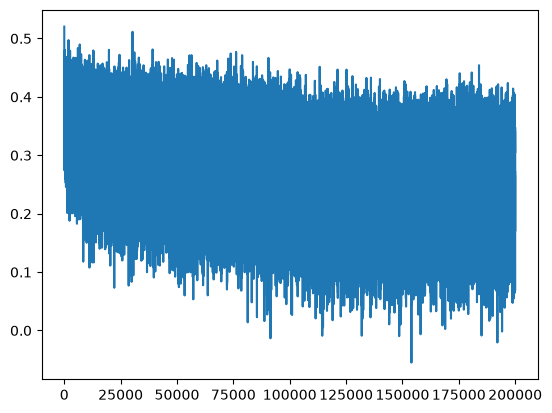

In [37]:
plt.plot(stepi, lossi)

In [38]:
print(loss.item()) # Got very far from the biagram model in terms of loss value

1.867818832397461


In [39]:
N = Xtr.shape[0]
N

182438

In [40]:
# Network's seen values
emb = C[Xtr]                                 # (N, 10, 30)
h = torch.tanh(emb.view(-1, 300) @ W1 + b1)  # (N, 300)
logits = h @ W2 + b2                         # (N, 27)
loss = F.cross_entropy(logits, Ytr)
loss.item()

1.8085346221923828

In [50]:
N = Xdev.shape[0]
N

22878

In [51]:
# Network's unseen values (validation set)
emb = C[Xdev]                                # (Ndev, 10, 30)
h = torch.tanh(emb.view(-1, 300) @ W1 + b1)  # (Ndev, 300)
logits = h @ W2 + b2                         # (Ndev, 27)
loss = F.cross_entropy(logits, Ydev)
loss.item()

2.047844409942627

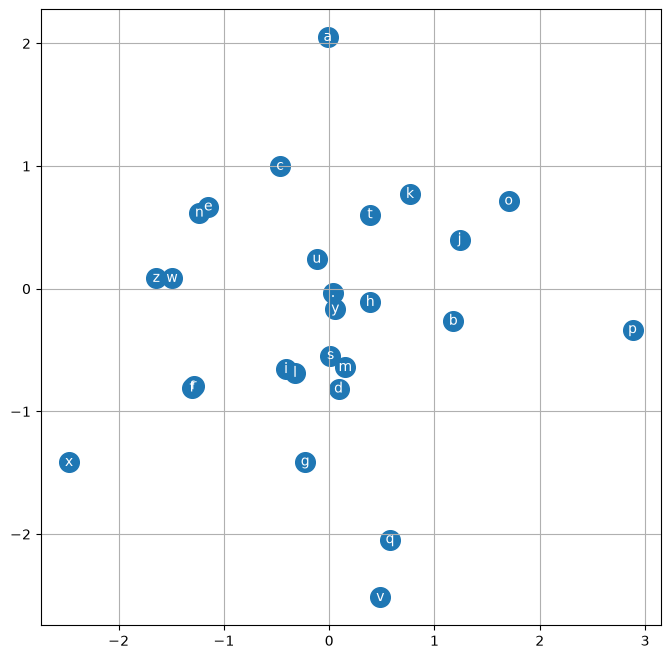

In [52]:
# visualize dimensions 0 and 1 of the embedding matrix C for all characters
plt.figure(figsize=(8,8))
plt.scatter(C[:, 0].detach().cpu(), C[:, 1].detach().cpu(), s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
plt.grid('minor')

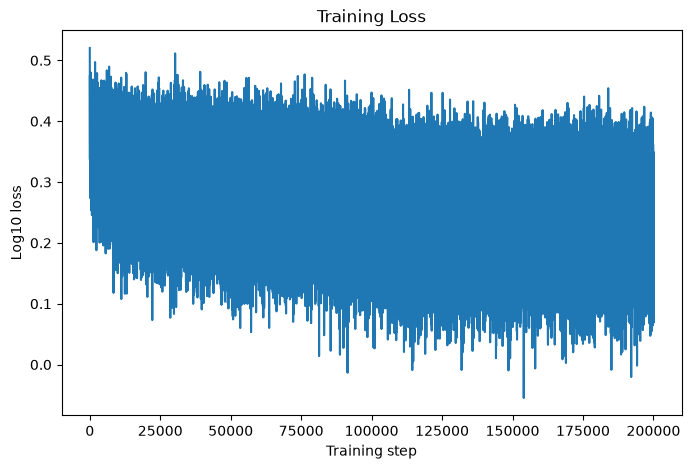

In [53]:
plt.figure(figsize=(8, 5))
plt.plot(stepi, lossi)
plt.xlabel("Training step")
plt.ylabel("Log10 loss")
plt.title("Training Loss")
plt.show()

In [54]:
context = [0] * block_size
C[torch.tensor([context])].shape

torch.Size([1, 10, 30])

In [55]:
with torch.no_grad():
    for p, best_p in zip(parameters, best_parameters):
        p.copy_(best_p)

print("Restored best model from step:", best_step)
print("Best validation loss:", best_val_loss)

Restored best model from step: 110000
Best validation loss: 2.0478445193663126


In [56]:
test_loss = split_loss(Xte, Yte)
print("Test loss:", test_loss)

Test loss: 2.023050308227539


In [60]:
# sample from the model

for _ in range(20):
    
    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      emb = C[torch.tensor([context])] # (1,block_size,d)
      h = torch.tanh(emb.view(1, -1) @ W1 + b1)
      logits = h @ W2 + b2
      probs = F.softmax(logits, dim=1)
      ix = torch.multinomial(probs, num_samples=1).item()
      context = context[1:] + [ix]
      out.append(ix)
      if ix == 0:
        break
    
    print(''.join(itos[i] for i in out))

nimita.
mahmari.
parlyng.
zarlin.
betileen.
makaim.
misha.
amordan.
alexzandra.
nadiyaashuw.
bryk.
charisell.
yianne.
sydrett.
cherrott.
gentanely.
alecha.
carmile.
eslin.
abyie.


In [49]:
# We can see that we are getting good results now
print(f"Final Results ---> Traning Loss: {split_loss(Xtr, Ytr)} | Validation Loss: {split_loss(Xdev, Ydev)} | Test Loss: {split_loss(Xte, Yte)}")

Final Results ---> Traning Loss: 1.8085346221923828 | Validation Loss: 2.047844409942627 | Test Loss: 2.023050308227539


In [355]:
# The Model is Performing Good when Compard to Biagram Model 
# But we have over fitted a little bit in this model as the traning and validation set have very high difference between them